# Lab 12: Social and Media Platform APIs

*INFO 4617/5617 · Week 12 · Chapter 12, [Social and Media Platform APIs](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-12-social.html)*

This week every class is live coding: one lab in three parts, one a day. Each step below says what we're building and why, and its code cell holds only the comments that frame it: we write the code live, in class. Nothing here is turned in. After each step, a **💬 Discuss** box holds questions to talk over before the next one; click it to open it.

We'll read what federal agencies post on two platforms:
- **Part 1, Monday:** **Bluesky**, whose public API answers anyone, with no account or key, and how to tell an agency's account from an impostor's;
- **Part 2, Wednesday:** more of Bluesky: more posts than one request returns, and what an agency's followers and reposts can show;
- **Part 3, Friday:** **YouTube**'s Data API, which needs a key, for the same agencies' videos.

Reddit and Spotify are in the chapter, as platforms that have closed much of what their APIs once offered, along with the archives that replaced Pushshift for Reddit data.

Along the way, short ⏱ microsprints ask you to change one thing, alone or in pairs, and share what you find.

**Before class:** open this notebook in the `webdata` environment (chapter 1), and have your email address ready for the User-Agent. Monday and Wednesday need no key. **For Friday, get a YouTube Data API key** from a personal Google account ([how](https://developers.google.com/youtube/v3/getting-started)), and store it as the environment variable `YOUTUBE_KEY`, one of week 11's three safe ways: set it, close the terminal, open a new one, and start Jupyter from there.

On Wednesday and Friday, start at that day's setup step, or run every cell above where we stopped (**Run → Run All Above Selected Cell**).

> **Instructor key.** Part 1 was written and run on 2026-11-02, the morning of its class; Parts 2 and 3 were added the same day, after chapter 12's rewrite (textbook #303), which this lab now follows: Bluesky's public AppView with `requests` and no login, then YouTube's Data API. The whole key was rerun on 2026-11-02 with `labs/tools/run_key.py`. Parts 1 and 2 ran; follower counts, posts, and the window five pages reach change daily. **Part 3 is not run live:** the cloud machine has no `YOUTUBE_KEY`, so its cells (Steps 8–10) are tagged `not-run-live` and have no outputs. Run them from a laptop with a key before Friday. Reposts are skipped so that no private person's post or handle appears in an output. Step 11's answers about YouTube are general until Part 3 runs.

# Part 1 — Monday: Bluesky, and who is posting

Bluesky is a social network built on an open protocol, the AT Protocol. Its public API answers anyone who asks, with no account and no key, the way Wikipedia's did in week 10. We start from an agency's profile page on the website, ask the API for the same profile, then compare the federal agencies that post there, and read what one of them posted this week.

## Step 0 — Set up (5 minutes)

Import what we need and define the User-Agent: Bluesky asks for no key, but every request still says who sent it, as Wikipedia's did. Every request today goes to Bluesky's public **AppView**, `https://public.api.bsky.app/xrpc/`, the service that answers reads for anyone ([API hosts](https://docs.bsky.app/docs/advanced-guides/api-directory)). Each method's name is part of the address: `app.bsky.actor.getProfile` reads a profile, `app.bsky.feed.getAuthorFeed` an account's posts. Each method has a page in Bluesky's [HTTP API reference](https://docs.bsky.app/docs/category/http-reference) listing its parameters and the fields it returns; keep it open beside the notebook.

In [1]:
# Import requests, pandas (as pd), and matplotlib.pyplot (as plt)
# Define HEADERS, whose "User-Agent" is "WebDataScience/1.0 (your-email@colorado.edu)", with your email
# bsky_base = "https://public.api.bsky.app/xrpc"
import requests
import pandas as pd
import matplotlib.pyplot as plt

HEADERS = {"User-Agent": "WebDataScience/1.0 (your-email@colorado.edu)"}
bsky_base = "https://public.api.bsky.app/xrpc"

<details>
<summary>💬 Discuss</summary>

- Census and FRED wanted a key; Bluesky doesn't. What does a key let an agency do that Bluesky gives up?
- Bluesky's protocol lets anyone run an AppView of their own. What would it mean for a researcher if the company's went away?

</details>

## Step 1 — From the website to the API: one agency's profile (8 minutes)

Open the National Weather Service's profile on the website, [bsky.app/profile/nws.noaa.gov](https://bsky.app/profile/nws.noaa.gov). Its **handle**, `nws.noaa.gov`, is a domain name: an account can take a domain as its handle only by proving it controls that domain ([Bluesky's guide](https://bsky.social/about/blog/4-28-2023-domain-handle-tutorial)), so no one but NOAA can post as `nws.noaa.gov`. The blue check beside its name is a second proof: Bluesky itself has **verified** the account ([how verification works](https://bsky.social/about/blog/04-21-2025-verification)). Now ask the API for the same page with [`app.bsky.actor.getProfile`](https://docs.bsky.app/docs/api/app-bsky-actor-get-profile), and find the website's numbers in its answer (the reference lists every field it returns, `followersCount` and `postsCount` among them), as the chapter's ["Who Is Posting: A Profile"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-12-social.html#who-is-posting-a-profile) reads one.

In [2]:
# profile: the JSON of f"{bsky_base}/app.bsky.actor.getProfile" with params={"actor": "nws.noaa.gov"} and HEADERS
# Print its handle, displayName, followersCount, postsCount, and createdAt; then its "verification"
profile = requests.get(f"{bsky_base}/app.bsky.actor.getProfile", params={"actor": "nws.noaa.gov"}, headers=HEADERS).json()
print(profile["handle"], "|", profile["displayName"])
print("followers:", profile["followersCount"], "| posts:", profile["postsCount"], "| joined:", profile["createdAt"][:10])
print(profile["verification"]["verifiedStatus"], "by", profile["verification"]["verifications"][0]["issuerHandle"])

nws.noaa.gov | National Weather Service
followers: 63023 | posts: 1394 | joined: 2025-01-17
valid by bsky.app


<details>
<summary>💬 Discuss</summary>

- Did the API's counts match the website's? If they differ by a few, why might that be?
- A search for "National Park Service" on Bluesky finds "Alt National Park Service" and "The National Park Service UNCENSORED", with no `.gov` handle and no check. What would a researcher who collected their posts as the agency's have got wrong?
- Which proof would you trust more, the domain or the check, and why?

</details>

## Step 2 — Five agencies in one table (8 minutes)

Five federal accounts have a `.gov` handle on Bluesky as of November 2026; four of them are NOAA's. Ask for each profile in a loop, keep the same five fields, and make a DataFrame, sorted by followers, as week 11 compared places. [`app.bsky.actor.getProfiles`](https://docs.bsky.app/docs/api/app-bsky-actor-get-profiles) can ask for up to 25 at once; one at a time keeps the loop plain.

In [3]:
# agencies: "noaa.gov", "nws.noaa.gov", "climate.noaa.gov", "noaacomms.noaa.gov", "federalreserve.gov"
# rows: for each handle, request its profile, and append a dict of handle, displayName, followersCount, postsCount, createdAt[:10]
# accounts: a DataFrame of rows, sorted by followersCount, largest first; show it
agencies = ["noaa.gov", "nws.noaa.gov", "climate.noaa.gov", "noaacomms.noaa.gov", "federalreserve.gov"]
rows = []
for handle in agencies:
    p = requests.get(f"{bsky_base}/app.bsky.actor.getProfile", params={"actor": handle}, headers=HEADERS).json()
    rows.append({"handle": p["handle"], "name": p["displayName"], "followers": p["followersCount"],
                 "posts": p["postsCount"], "joined": p["createdAt"][:10]})
accounts = pd.DataFrame(rows).sort_values("followers", ascending=False)
accounts

,handle,name,followers,posts,joined
1,nws.noaa.gov,National Weather Service,63023,1394,2025-01-17
2,climate.noaa.gov,NOAA Climate.gov,46965,93,2025-01-14
0,noaa.gov,NOAA,41938,150,2025-01-14
4,federalreserve.gov,Federal Reserve,8405,1029,2024-12-06
3,noaacomms.noaa.gov,NOAA Communications,5620,117,2025-01-14


### ⏱ Microsprint (3 minutes, alone or in pairs)

Not every official account has a domain handle. The Library of Congress posts as `librarycongress.bsky.social`, and the Federal Reserve Bank of St. Louis, FRED's home in week 11, as `stlouisfed.bsky.social`.

**Do:** add both to the loop, and print each account's `verification` status ([`getProfile`'s reference](https://docs.bsky.app/docs/api/app-bsky-actor-get-profile) describes the field; [how verification works](https://bsky.social/about/blog/04-21-2025-verification)).
**Share:** which of the seven are verified, and how you'd tell an official `.bsky.social` account from an impostor's.

In [4]:
# Microsprint: for "librarycongress.bsky.social" and "stlouisfed.bsky.social", request the profile
# Print each handle, its followersCount, and its verification's verifiedStatus
for handle in ["librarycongress.bsky.social", "stlouisfed.bsky.social"]:
    p = requests.get(f"{bsky_base}/app.bsky.actor.getProfile", params={"actor": handle}, headers=HEADERS).json()
    print(p["handle"], "|", p["followersCount"], "|", p["verification"]["verifiedStatus"])

librarycongress.bsky.social | 9237 | valid


stlouisfed.bsky.social | 1121 | valid


<details>
<summary>💬 Discuss</summary>

- Most federal agencies, the Census Bureau and NASA among them, have no `.gov` handle on Bluesky. What does that say about which agencies a study of "government on Bluesky" would see?
- The National Weather Service has more followers than NOAA, its parent. What might explain it?
- The Federal Reserve joined first but has the fewest followers. Is followers the right measure of an agency's reach?

</details>

## Step 3 — What an agency posted this week (10 minutes)

[`app.bsky.feed.getAuthorFeed`](https://docs.bsky.app/docs/api/app-bsky-feed-get-author-feed) returns an account's posts, newest first, up to 100 a request. Its reference lists the values `filter` takes; with `filter="posts_no_replies"` it leaves out the account's replies, but it still includes its **reposts**: other people's posts it shared, which carry a `"reason"`. Those authors may be private people, so skip any item with a reason, and keep each post's time, its counts, and the start of its text.

In [5]:
# feed: the JSON's "feed" of f"{bsky_base}/app.bsky.feed.getAuthorFeed", params actor="nws.noaa.gov", limit=25, filter="posts_no_replies"
# posts: for each item without a "reason" (not a repost), a dict of its post's indexedAt[:16], likeCount, repostCount, replyCount, and record text[:70]
# nws_posts: a DataFrame of posts; show it sorted by repostCount, largest first, the top 5
params = {"actor": "nws.noaa.gov", "limit": 25, "filter": "posts_no_replies"}
feed = requests.get(f"{bsky_base}/app.bsky.feed.getAuthorFeed", params=params, headers=HEADERS).json()["feed"]
posts = []
for item in feed:
    if "reason" in item:
        continue
    post = item["post"]
    posts.append({"time": post["indexedAt"][:16], "likes": post["likeCount"], "reposts": post["repostCount"],
                  "replies": post["replyCount"], "text": post["record"]["text"][:70]})
nws_posts = pd.DataFrame(posts)
print(len(feed), "items,", len(nws_posts), "of them the agency's own posts")
nws_posts.sort_values("reposts", ascending=False).head(5)

25 items, 25 of them the agency's own posts


,time,likes,reposts,replies,text
0,2026-10-31T18:01,206,80,1,Daylight Saving Time ends at 2am overnight ton...
1,2026-10-30T20:59,89,33,3,Updated Extreme Rainfall Outlook for Sunday:\n...
23,2026-10-20T16:10,118,33,3,Here's a more detailed look at the expected ra...
20,2026-10-21T19:55,120,32,1,A subtropical storm could form later today or ...
21,2026-10-21T14:27,90,31,0,A rare risk for tornadoes and severe weather e...


### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** run the same request for another of the five agencies.
**Share:** the agency, how many of its 25 items were its own posts rather than reposts, and the topic of its most-reposted post.

In [6]:
# Microsprint: set params["actor"] to another agency; request again, build the DataFrame the same way, and show its top 3 by reposts
params["actor"] = "federalreserve.gov"
feed = requests.get(f"{bsky_base}/app.bsky.feed.getAuthorFeed", params=params, headers=HEADERS).json()["feed"]
posts = []
for item in feed:
    if "reason" in item:
        continue
    post = item["post"]
    posts.append({"time": post["indexedAt"][:16], "likes": post["likeCount"], "reposts": post["repostCount"],
                  "replies": post["replyCount"], "text": post["record"]["text"][:70]})
fed_posts = pd.DataFrame(posts)
print(len(feed), "items,", len(fed_posts), "of them the agency's own posts")
fed_posts.sort_values("reposts", ascending=False).head(3)

25 items, 25 of them the agency's own posts


,time,likes,reposts,replies,text
7,2026-10-28T20:30,5,5,0,Watch Chairman Warsh’s statement from the #FOM...
12,2026-10-28T14:22,1,4,0,WATCH LIVE TODAY: Press conference with #FOMC ...
13,2026-10-27T14:07,6,3,2,Tomorrow at 2:30 p.m. ET: Chairman Warsh hosts...


<details>
<summary>💬 Discuss</summary>

- Which kinds of posts got reposted most: warnings, explainers, or announcements? What would you need to say a kind of post *causes* reposts?
- We skipped reposts to keep private people's posts out of our table. What does an agency's reposting tell you that its own posts don't, and how could you study it without printing anyone's handle?
- The feed's last item came with a `cursor`. What do you think it's for? (Week 10's `continue` is a hint.)

</details>

## End of Part 1

On Wednesday, Part 2 follows the `cursor` to read more than one request returns, and asks what an agency's followers and posting rhythm can show. It starts with its own setup step, so you don't need today's cells to have run.

**Before Friday:** get your YouTube Data API key, from a personal Google account, and store it as `YOUTUBE_KEY`.

# Part 2 — Wednesday: more of Bluesky, and an agency's rhythm

One request returns at most 100 posts. Today we follow the `cursor` to read more, as week 10 followed Wikipedia's `continue`, and then ask what half a year of an agency's posts shows: when it posts, and which posts travel.

## Step 4 — Set up again (3 minutes)

Part 2 starts fresh, so a student who missed Monday can start here. Import what we need, define the User-Agent, and set `bsky_base`, as in Step 0. No key today either. Today's one method is Monday's [`app.bsky.feed.getAuthorFeed`](https://docs.bsky.app/docs/api/app-bsky-feed-get-author-feed).

In [7]:
# Import requests, pandas (as pd), and matplotlib.pyplot (as plt); define HEADERS as in Step 0, with your email
# bsky_base = "https://public.api.bsky.app/xrpc"
import requests
import pandas as pd
import matplotlib.pyplot as plt

HEADERS = {"User-Agent": "WebDataScience/1.0 (your-email@colorado.edu)"}
bsky_base = "https://public.api.bsky.app/xrpc"

<details>
<summary>💬 Discuss</summary>

- Monday's request returned 25 posts. How many do you think the National Weather Service has posted since it joined, and how would you find out without reading them all?

</details>

## Step 5 — More than one page: the `cursor` (12 minutes)

Monday's answer ended with a **cursor**. Send it back as the `cursor` parameter ([`getAuthorFeed`'s reference](https://docs.bsky.app/docs/api/app-bsky-feed-get-author-feed)), and the next request returns the page that follows; when an answer has no cursor, there's nothing more. It's week 10's `continue` again: you send back what the server gave you, without needing to know what it means, as the chapter's ["More Than One Page: the `cursor`"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-12-social.html#more-than-one-page-the-cursor) shows. Take it in three moves: the first page by hand, the second by hand with the first page's cursor, then a given loop that reads up to five pages and stops.

In [8]:
# params: actor="nws.noaa.gov", limit=100, filter="posts_no_replies"; first: the JSON of getAuthorFeed with them
# Print how many items came back, the newest and oldest createdAt, and the cursor
params = {"actor": "nws.noaa.gov", "limit": 100, "filter": "posts_no_replies"}
first = requests.get(f"{bsky_base}/app.bsky.feed.getAuthorFeed", params=params, headers=HEADERS).json()
print(len(first["feed"]), "items, from", first["feed"][0]["post"]["record"]["createdAt"][:10],
      "back to", first["feed"][-1]["post"]["record"]["createdAt"][:10])
print("cursor:", first["cursor"])

100 items, from 2026-10-31 back to 2026-10-02
cursor: 2026-10-02T14:45:45.751Z


In [9]:
# Add the first page's cursor to params; second: the JSON of the same request; print the same three things
params["cursor"] = first["cursor"]
second = requests.get(f"{bsky_base}/app.bsky.feed.getAuthorFeed", params=params, headers=HEADERS).json()
print(len(second["feed"]), "items, from", second["feed"][0]["post"]["record"]["createdAt"][:10],
      "back to", second["feed"][-1]["post"]["record"]["createdAt"][:10])
print("cursor:", second["cursor"])

100 items, from 2026-10-01 back to 2026-08-26
cursor: 2026-08-26T00:51:32.774Z


In [10]:
# Given: read up to five pages of an account's posts, skipping reposts; it stops early when there's no cursor
actor = "nws.noaa.gov"
posts = []
cursor = None
pages = 0
while True:
    params = {"actor": actor, "limit": 100, "filter": "posts_no_replies"}
    if cursor:
        params["cursor"] = cursor
    page = requests.get(f"{bsky_base}/app.bsky.feed.getAuthorFeed", params=params, headers=HEADERS).json()
    pages += 1
    for item in page["feed"]:
        if "reason" in item:
            continue
        post = item["post"]
        posts.append({"created": post["record"]["createdAt"], "likes": post["likeCount"],
                      "reposts": post["repostCount"], "replies": post["replyCount"],
                      "embed": post["record"].get("embed", {}).get("$type", "none")})
    cursor = page.get("cursor")
    if not cursor or pages == 5:
        break
nws = pd.DataFrame(posts)
nws["created"] = pd.to_datetime(nws["created"], format="ISO8601", utc=True)
print(pages, "pages,", len(nws), "posts, from", nws["created"].min().date(), "to", nws["created"].max().date())

5 pages, 495 posts, from 2026-04-20 to 2026-10-31


<details>
<summary>💬 Discuss</summary>

- The loop stops at five pages, though the fifth still had a cursor. When would you stop on a count, on a date, or only at the end? What would you write so a reader knows which?
- Week 10's `continue`, week 11's EIA `offset`, and Bluesky's `cursor`: which of them asks you to keep count, and which keeps count for you?
- The loop has no error handling. If Bluesky answered a page with an error, which line would fail, and what would `nws` hold?

</details>

## Step 6 — When an agency posts (10 minutes)

Each post's `createdAt` is in UTC (Coordinated Universal Time). Convert them to the agency's own time zone with [`dt.tz_convert()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.tz_convert.html), Eastern for the Weather Service's headquarters, then count posts by weekday with [`dt.day_name()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.day_name.html), and draw them, as the chapter's ["When an Agency Posts, and What Travels"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-12-social.html#when-an-agency-posts-and-what-travels) does.

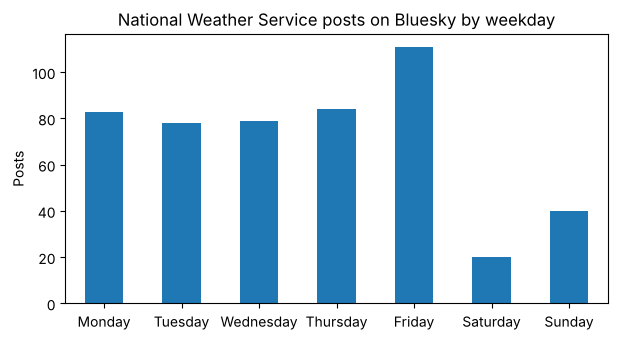

created
Monday        83
Tuesday       78
Wednesday     79
Thursday      84
Friday       111
Saturday      20
Sunday        40


In [11]:
# local: nws["created"] converted to "America/New_York"; days: Monday to Sunday, in order
# by_day: local's day names counted, reindexed by days; plot it as bars with a title and a y label; print it
local = nws["created"].dt.tz_convert("America/New_York")
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = local.dt.day_name().value_counts().reindex(days)
ax = by_day.plot.bar(figsize=(7, 3.5), rot=0)
ax.set(title="National Weather Service posts on Bluesky by weekday", ylabel="Posts", xlabel="")
plt.show()
print(by_day.to_string())

### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** set `actor` in the given loop to another agency, `federalreserve.gov` or `climate.noaa.gov`, run the loop and this step again, and change the title.
**Share:** the agency, how far back five pages reached, and its busiest weekday.

In [12]:
# Microsprint: in the given loop, set actor to another agency and run it; then run this step's lines again for it
# (The key reruns the loop here for federalreserve.gov, so that nws keeps the Weather Service's posts for Step 7)
fed_posts = []
cursor = None
pages = 0
while True:
    params = {"actor": "federalreserve.gov", "limit": 100, "filter": "posts_no_replies"}
    if cursor:
        params["cursor"] = cursor
    page = requests.get(f"{bsky_base}/app.bsky.feed.getAuthorFeed", params=params, headers=HEADERS).json()
    pages += 1
    for item in page["feed"]:
        if "reason" in item:
            continue
        fed_posts.append({"created": item["post"]["record"]["createdAt"]})
    cursor = page.get("cursor")
    if not cursor or pages == 5:
        break
fed = pd.DataFrame(fed_posts)
fed["created"] = pd.to_datetime(fed["created"], format="ISO8601", utc=True)
print(len(fed), "posts, from", fed["created"].min().date(), "to", fed["created"].max().date())
print(fed["created"].dt.tz_convert("America/New_York").dt.day_name().value_counts().reindex(days).to_string())

500 posts, from 2026-02-20 to 2026-10-30
created
Monday        38
Tuesday       74
Wednesday    109
Thursday     141
Friday       133
Saturday       3
Sunday         2


<details>
<summary>💬 Discuss</summary>

- The weather doesn't take weekends off. Why might an agency's posts?
- Why convert to the agency's time zone rather than yours, and what would a count by hour look like if you forgot?
- What would you need to know to say *why* the busiest day is the busiest?

</details>

## Step 7 — What travels (6 minutes)

Each post's `embed` says what it carries: `app.bsky.embed.images`, a video, a link card (`external`), or a quoted post (`record`); Bluesky's [Posts in-depth](https://docs.bsky.app/docs/about-bluesky-content/posts) describes each kind. Group the posts by it with [`groupby()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html), and compare the number of posts and their median reposts.

In [13]:
# Group nws by "embed"; for "reposts", show the count and the median, sorted by count, largest first
nws.groupby("embed")["reposts"].agg(["count", "median"]).sort_values("count", ascending=False)

,count,median
embed,,
app.bsky.embed.images,412,19.0
app.bsky.embed.video,59,23.0
app.bsky.embed.external,13,14.0
app.bsky.embed.recordWithMedia,5,23.0
app.bsky.embed.record,3,24.0
none,3,28.0


<details>
<summary>💬 Discuss</summary>

- Almost every post carries an image. What does that do to a comparison of images against videos?
- A post's reach depends on the weather it warns about. What would you need, beyond this table, to say a format *causes* reposts?
- We've read only the agency's own posts. What could its replies, which we left out, tell you, and what would collecting them ask of you?

</details>

## End of Part 2

On Friday, Part 3 asks YouTube's Data API about the same agencies' videos. It needs a key: get it today if you haven't, from a personal Google account, and store it as `YOUTUBE_KEY` (the deck's "Before Friday: your YouTube key"). Part 3 starts with its own setup step, so you don't need today's cells to have run.

# Part 3 — Friday: YouTube's Data API, and a key that counts

YouTube answers anyone with a key, and counts every request against a daily quota. We find an agency's channel by its handle, read its newest videos and their statistics, and count what it cost.

## Step 8 — Set up, and check your key (5 minutes)

Import what we need, define the User-Agent, and check `YOUTUBE_KEY` before reading it, as week 11 did. If it says `MISSING`, quit Jupyter, open a new terminal, and start it again from there; if you can't restart now, the given cell asks for the key with [`getpass()`](https://docs.python.org/3/library/getpass.html), only if it's missing: run it, paste the key into the box that opens, and press Enter. Google's [Obtaining authorization credentials](https://developers.google.com/youtube/registering_an_application) covers API keys, and the chapter's ["Getting and Storing a Key"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-12-social.html#getting-and-storing-a-key) has the steps to make one.

In [14]:
# Import os, requests, and pandas (as pd); define HEADERS as in Step 0, with your email
# Print whether "YOUTUBE_KEY" is set or MISSING; yt_base = "https://www.googleapis.com/youtube/v3"
import os
import requests
import pandas as pd

HEADERS = {"User-Agent": "WebDataScience/1.0 (your-email@colorado.edu)"}
print("YOUTUBE_KEY:", "set" if "YOUTUBE_KEY" in os.environ else "MISSING")
yt_base = "https://www.googleapis.com/youtube/v3"

YOUTUBE_KEY: MISSING


In [ ]:
# Given: only if the check said MISSING, ask for the key with getpass. If it said set, this does nothing
from getpass import getpass
if not os.environ.get("YOUTUBE_KEY"):
    os.environ["YOUTUBE_KEY"] = getpass("YOUTUBE_KEY isn't set. Paste it here: ")

In [ ]:
# Now it's set: read YOUTUBE_KEY into youtube_key with os.environ[...]
youtube_key = os.environ["YOUTUBE_KEY"]

<details>
<summary>💬 Discuss</summary>

- Bluesky asked for no key; YouTube does. What does a key let Google do that Bluesky can't?
- The key goes in the URL, so `response.url` contains it. Where could it end up if you printed the URL?

</details>

## Step 9 — A channel by its handle (8 minutes)

[`channels.list`](https://developers.google.com/youtube/v3/docs/channels/list) finds a channel by its handle with `forHandle`. `part` names the groups of fields you want, each described in the [channel resource](https://developers.google.com/youtube/v3/docs/channels): `snippet` (the name), `statistics` (the counts), and `contentDetails`, which holds the ID of the playlist of every video the channel has uploaded. Ask for NOAA's channel, `@NOAA`, and compare its counts with [the channel's page](https://www.youtube.com/@NOAA).

In [ ]:
# params: part="snippet,statistics,contentDetails", forHandle="@NOAA", key=youtube_key; channel: the JSON's "items"[0] of f"{yt_base}/channels"
# Print its title, subscriberCount, and videoCount; uploads: its contentDetails' relatedPlaylists' "uploads"
params = {"part": "snippet,statistics,contentDetails", "forHandle": "@NOAA", "key": youtube_key}
channel = requests.get(f"{yt_base}/channels", params=params, headers=HEADERS).json()["items"][0]
print(channel["snippet"]["title"], "| subscribers:", channel["statistics"]["subscriberCount"],
      "| videos:", channel["statistics"]["videoCount"])
uploads = channel["contentDetails"]["relatedPlaylists"]["uploads"]

### ⏱ Microsprint (3 minutes, alone or in pairs)

**Do:** ask for another agency's channel: `@NOAAClimate`, `@federalreserve`, `@stlouisfed`, `@uscensusbureau`, or `@NASA`.
**Share:** the channel, its subscribers and videos, and how they compare with the agency's Bluesky followers from Monday.

In [ ]:
# Microsprint: set params["forHandle"] to another agency's handle; request again; print the same three things
params["forHandle"] = "@federalreserve"
other = requests.get(f"{yt_base}/channels", params=params, headers=HEADERS).json()["items"][0]
print(other["snippet"]["title"], "| subscribers:", other["statistics"]["subscriberCount"],
      "| videos:", other["statistics"]["videoCount"])

<details>
<summary>💬 Discuss</summary>

- YouTube rounds `subscriberCount` down to three significant figures. What can't you measure because of that?
- How do you know `@NOAA` is NOAA's? Where would you check?

</details>

## Step 10 — A channel's newest videos (10 minutes)

[`playlistItems.list`](https://developers.google.com/youtube/v3/docs/playlistItems/list) on the uploads playlist returns the newest 50 videos' IDs; [`videos.list`](https://developers.google.com/youtube/v3/docs/videos/list) takes up to 50 IDs, joined with commas, and returns their statistics (the [video resource](https://developers.google.com/youtube/v3/docs/videos) lists them). Counts arrive as strings, and a video whose owner hid its likes has no `likeCount`, so convert with `int()` and use `.get()` with a default. Each request costs 1 unit of the project's 10,000 a day ([quota costs](https://developers.google.com/youtube/v3/determine_quota_cost)).

In [ ]:
# items: the JSON's "items" of f"{yt_base}/playlistItems" with part="contentDetails", playlistId=uploads, maxResults=50, key=youtube_key
# video_ids: each item's contentDetails' videoId; then the JSON's "items" of f"{yt_base}/videos" with part="snippet,statistics", id=video_ids joined by ",", key=youtube_key
# videos: a DataFrame of each video's publishedAt[:10], title[:50], viewCount and likeCount as ints (0 if missing); show the top 5 by views
params = {"part": "contentDetails", "playlistId": uploads, "maxResults": 50, "key": youtube_key}
items = requests.get(f"{yt_base}/playlistItems", params=params, headers=HEADERS).json()["items"]
video_ids = []
for item in items:
    video_ids.append(item["contentDetails"]["videoId"])
params = {"part": "snippet,statistics", "id": ",".join(video_ids), "key": youtube_key}
rows = []
for v in requests.get(f"{yt_base}/videos", params=params, headers=HEADERS).json()["items"]:
    rows.append({"published": v["snippet"]["publishedAt"][:10], "title": v["snippet"]["title"][:50],
                 "views": int(v["statistics"].get("viewCount", 0)), "likes": int(v["statistics"].get("likeCount", 0))})
videos = pd.DataFrame(rows)
videos.sort_values("views", ascending=False).head(5)

<details>
<summary>💬 Discuss</summary>

- Those two requests cost 2 units. How many units would a year of NOAA's uploads cost, and could you collect it in one day?
- We set a missing `likeCount` to 0. When is that wrong, and how would you count how often it happened?
- A search for the same videos is capped at 100 a day. Why might YouTube price a search differently from a list?

</details>

## Step 11 — What did we learn? (3 minutes)

In a few sentences, as comments:

- Monday asked who is posting. How did you tell an agency's account from an impostor's, and which proof would you trust more?
- Bluesky's `cursor` and YouTube's `nextPageToken` ([YouTube's paging guide](https://developers.google.com/youtube/v3/guides/implementation/pagination)) both page through a list. What did each ask of you, and what did each give in return?
- We skipped reposts and never printed a reply. What did that keep out of our data, and what did it cost us?
- Which of this week's numbers would be different if you ran this notebook next week, and which wouldn't?

**Recommended Exercises ahead** (in the chapter's companion notebook, due Sunday):

- Step 1, check who you're asking about: Monday's Steps 1–2, the handle and `verification`.
- Steps 2 and 4, an account's September posts: Step 5's cursor loop, stopping at a date instead of a count, and Monday's Step 3 for skipping reposts.
- Step 3, describe the month: Step 6's time zones and weekdays, and Step 7's `embed`.
- Step 5, compare: Step 6's bar chart, with two accounts.
- Step 6, interpret: the Discuss questions after Steps 6 and 7.

In [ ]:
# Your answers here, as comments
# 1. Two proofs: a .gov handle, which only whoever controls the domain can take, and Bluesky's verification. All five
#    .gov accounts and the two .bsky.social ones (the Library of Congress, the St. Louis Fed) had a valid verification;
#    "Alt National Park Service" had neither. I'd trust the domain more: it doesn't depend on Bluesky's judgment.
# 2. Bluesky's cursor asked nothing of us but to send it back: five pages of 100 reached from April 20 to October 31
#    for the Weather Service, and back to February 20 for the Federal Reserve. YouTube's nextPageToken works the same
#    way, but every page carries the key and costs a unit of the day's quota.
# 3. Skipping reposts kept other people's posts, perhaps private people's, out of our tables (there were none in the
#    Weather Service's last 25 items, but we couldn't know that in advance). It cost us what an agency chooses to
#    amplify, which says something about it too.
# 4. Follower counts, the newest posts, and which window five pages reach change every day; the weekday pattern
#    (Fridays for the Weather Service, Wednesday to Friday for the Fed) should hold. YouTube's subscriber counts are
#    rounded, so a small change won't show at all.

## Friday: your portfolio checkpoint (15 minutes)

The last 15 minutes go to your project. This week's checkpoint, **Collect and clean your data**, is due Sunday, November 8:

- **Collection code** that runs, makes polite requests (a User-Agent that identifies you, pauses between requests), and saves the raw data;
- **a cleaning step**, with its code and output, that produces a tidy dataset;
- **a small sample** of the cleaned data in your repository, with a data dictionary;
- **the README's Data section**: the source, when you collected it, how many records, and what you kept out of the repository and why.

Use the time to run your collection code once, here, where you can ask. If your data comes from a platform, its terms of service decide what you may put in a public repository, and this week's rule holds for your project too: keep private people out of what you save and show.